<div style="background:#eaf3ff;padding:16px;border-radius:8px;border-left:6px solid #1D4ED8;">
  <h1><font color="#1D4ED8"><b>KSU iCARE Lab — First-Year Scholars Program (2026–2027)</b></font></h1>
  <h2><font color="#0E7490"><b>Notebook: PyTorch Intro — Tensors and the Deep-Learning Workflow</b></font></h2>
  <p><font color="#334155"><b>Session Date:</b> November 4, 2026 &nbsp;|&nbsp; <b>Prerequisite:</b> No math or AI background required!</font></p>
</div>

<p><font color="#334155">Welcome to your first step into <b>Deep Learning with PyTorch</b>! If you have never taken calculus, linear algebra, or computer science, relax—you are in the right place. At its core, deep learning is simply a game of <b>"Guess the Secret Rule"</b> between an input <b><code>x</code></b> and an output <b><code>y</code></b>.</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:10px;margin-bottom:10px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Lesson</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What You Will Learn</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>The "x → y" Intuition</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. The "Guess the Rule" Game</b></td>
  <td style="padding:7px">How inputs (<code>x</code>) connect to outputs (<code>y</code>) using a multiplier <code>w</code> and a starting value <code>c</code>: <b><code>y = w * x + c</code></b></td>
  <td style="padding:7px"><i>"If <code>x = 1</code> gives <code>y = 5</code>, and <code>x = 2</code> gives <code>y = 7</code>, what is <code>w</code> and what is <code>c</code>?"</i></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Meet PyTorch Tensors</b></td>
  <td style="padding:7px">Creating <code>torch.tensor()</code> arrays, checking <code>.shape</code> and <code>.dtype</code>, and converting from NumPy</td>
  <td style="padding:7px"><i>"If <code>x = [1, 2, 3]</code>, what would <code>y</code> be for all three numbers at once?"</i></td>
</tr>
<tr>
  <td style="padding:7px"><b>3. Guessing &amp; Measuring Error (Loss)</b></td>
  <td style="padding:7px">Making an initial guess (<b>Forward Pass</b>) and measuring how far off the guess is (<b>Loss</b>)</td>
  <td style="padding:7px"><i>"If true <code>y</code> is <code>[5, 7, 9]</code>, but our guessed rule predicts <code>[1, 2, 3]</code>, how big is our mistake?"</i></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. PyTorch's Magic Compass (Gradients)</b></td>
  <td style="padding:7px">Turning on <code>requires_grad=True</code> and calling <code>loss.backward()</code> to see which way to nudge <code>w</code> and <code>c</code></td>
  <td style="padding:7px"><i>"Should we push <code>w</code> and <code>c</code> UP or DOWN to make our mistake smaller?"</i></td>
</tr>
<tr>
  <td style="padding:7px"><b>5. The Deep-Learning Training Loop</b></td>
  <td style="padding:7px">Teaching PyTorch to automatically discover the secret <code>w</code> and <code>c</code> from data</td>
  <td style="padding:7px"><i>"Start with a blind guess (<code>w=0, c=0</code>) and watch PyTorch discover <code>w=2, c=3</code> by itself!"</i></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>6. Medical Imaging Workflow</b></td>
  <td style="padding:7px">Using PyTorch to learn organ volume rules and classify dark vs. bright CT pixels</td>
  <td style="padding:7px"><i>"If a CT pixel has brightness <code>x</code>, what is the probability <code>y</code> that it belongs to the aorta?"</i></td>
</tr>
</table>


<hr>
<h2><font color="#1D4ED8"><b>1. What Is Deep Learning? The "Guess the Rule" Game (y = w * x + c)</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Before we touch PyTorch, let's see how <b>your own brain</b> learns a pattern from examples. Suppose a friend gives you an input number <b><code>x</code></b> and tells you the output number <b><code>y</code></b>:</font></p>

<ul>
  <li><font color="#334155"><b>Puzzle A (Multiplier only):</b> If <code>x = 1</code>, then <code>y = 2</code>. &nbsp; If <code>x = 2</code>, then <code>y = 4</code>. &nbsp; If <code>x = 3</code>, then <code>y = 6</code>. &nbsp; <b>If <code>x = 4</code>, what would <code>y</code> be?</b></font><br>
  <font color="#0E7490">Your brain immediately spots the rule: <b>multiply <code>x</code> by 2!</b> So if <code>x = 4</code>, then <code>y = 8</code>.</font></li>
  <li><font color="#334155"><b>Puzzle B (Multiplier + Starting Value):</b> Now suppose: If <code>x = 0</code>, then <code>y = 3</code>. &nbsp; If <code>x = 1</code>, then <code>y = 5</code>. &nbsp; If <code>x = 2</code>, then <code>y = 7</code>. &nbsp; <b>If <code>x = 3</code>, what would <code>y</code> be?</b></font><br>
  <font color="#0E7490">Look at how <code>y</code> changes: every time <code>x</code> goes up by <code>1</code>, <code>y</code> goes up by <b><code>2</code></b>. And when <code>x = 0</code>, <code>y</code> starts at <b><code>3</code></b>! So the rule is: <b>multiply <code>x</code> by 2, and then add 3</b>. If <code>x = 3</code>, then <code>y = 2 * 3 + 3 = 9</code>!</font></li>
</ul>

<p><font color="#334155">In AI and Deep Learning, we write this everyday rule using two simple letters—<b><code>w</code></b> and <b><code>c</code></b>:</font></p>
<p align="center"><font color="#1D4ED8" size="4"><b><code>y = w * x + c</code></b></font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Letter</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Means in Plain English</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>How to Find It from Examples</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b><code>x</code></b></td>
  <td style="padding:7px"><b>Input</b> (what you know, like number of CT slices or cups of coffee)</td>
  <td style="padding:7px">Given to you in the data.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b><code>y</code></b></td>
  <td style="padding:7px"><b>Output</b> (what you want to predict, like total scan time or total price)</td>
  <td style="padding:7px">Given to you in the training examples.</td>
</tr>
<tr>
  <td style="padding:7px"><b><code>w</code></b></td>
  <td style="padding:7px"><b>Weight (Multiplier / Step Size):</b> How much <code>y</code> jumps when <code>x</code> goes up by <code>1</code></td>
  <td style="padding:7px"><code>w = (change in y) / (change in x)</code></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b><code>c</code></b></td>
  <td style="padding:7px"><b>Constant (Bias / Starting Value):</b> What <code>y</code> equals when <code>x = 0</code></td>
  <td style="padding:7px">Once you know <code>w</code>, plug in any pair: <code>c = y - (w * x)</code></td>
</tr>
</table>

<p><font color="#A34F00"><b>How Traditional Coding vs. Deep Learning Differ:</b></font></p>
<ul>
  <li><font color="#334155"><b>Traditional Coding:</b> You already know <code>w = 2</code> and <code>c = 3</code>, and you ask the computer to calculate <code>y</code> for a new <code>x</code>.</font></li>
  <li><font color="#177345"><b>Deep Learning (PyTorch):</b> You only have examples of <code>x</code> and <code>y</code>, and <b>PyTorch automatically figures out <code>w</code> and <code>c</code> for you!</b></font></li>
</ul>

<h3><font color="#0E7490"><b>Worked example 1: Find <code>w</code> and <code>c</code> from an everyday example and predict a new <code>y</code></b></font></h3>
<p><font color="#334155"><b>Real-life scenario:</b> A medical imaging lab orders boxes of gloves. There is a fixed shipping fee (<code>c</code>) plus a price per box (<code>w</code>):</font></p>
<ul>
  <li><font color="#334155">If you order <b><code>x = 1</code></b> box, the total cost is <b><code>y = 15</code></b> dollars.</font></li>
  <li><font color="#334155">If you order <b><code>x = 2</code></b> boxes, the total cost is <b><code>y = 25</code></b> dollars.</font></li>
  <li><font color="#0E7490"><b>Question:</b> What are <code>w</code> and <code>c</code>? And <b>if <code>x = 5</code> boxes, what would <code>y</code> be?</b></font></li>
</ul>
<p><font color="#334155"><b>Step 1 (Find <code>w</code>):</b> When <code>x</code> went from <code>1</code> to <code>2</code> (up by 1), <code>y</code> went from <code>15</code> to <code>25</code> (up by <b><code>10</code></b>). So <b><code>w = 10</code></b> dollars per box!</font><br>
<font color="#334155"><b>Step 2 (Find <code>c</code>):</b> For <code>x = 1</code>, <code>w * x = 10 * 1 = 10</code>. To reach <code>y = 15</code>, we need to add <b><code>5</code></b>. So <b><code>c = 5</code></b> dollars shipping fee!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to verify our <code>w</code> and <code>c</code> and find <code>y</code> when <code>x = 5</code>. <font color="#0E7490"><b>Expected output:</b></font> <code>w = 10</code>, <code>c = 5</code>, and <code>If x = 5, then y = 55</code>.</p>


In [1]:
# Known examples: (x1 = 1, y1 = 15) and (x2 = 2, y2 = 25)
x1, y1 = 1, 15
x2, y2 = 2, 25

# 1. Compute w (how much y changes when x increases by 1)
w = (y2 - y1) / (x2 - x1)

# 2. Compute c (the constant starting value: c = y1 - w * x1)
c = y1 - (w * x1)

# 3. Predict y for a brand-new input: x = 5
x_new = 5
y_new = w * x_new + c

print("Discovered weight (w):", int(w))
print("Discovered constant (c):", int(c))
print("If x = 5, then y =", int(y_new))


Discovered weight (w): 10
Discovered constant (c): 5
If x = 5, then y = 55


<h3><font color="#0E7490"><b>Worked example 2: Medical Imaging Rule — CT Scan Time from Number of Slices</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Let's apply the exact same <code>y = w * x + c</code> puzzle to a CT scanner in the hospital! Every scan takes a fixed setup time <b><code>c</code></b> (positioning the patient on the table) plus <b><code>w</code></b> seconds for each CT slice <b><code>x</code></b>:</font></p>
<ul>
  <li><font color="#334155"><b>If <code>x = 10</code> slices</b>, the total time is <b><code>y = 50</code> seconds</b>.</font></li>
  <li><font color="#334155"><b>If <code>x = 20</code> slices</b>, the total time is <b><code>y = 70</code> seconds</b>.</font></li>
  <li><font color="#0E7490"><b>Question:</b> What are <code>w</code> (seconds per slice) and <code>c</code> (setup time in seconds)? And <b>if a scan has <code>x = 30</code> slices, what would <code>y</code> be?</b></font></li>
</ul>
<p><font color="#334155">Let's check the jump: when <code>x</code> increased by <code>10</code> slices (from 10 to 20), <code>y</code> increased by <code>20</code> seconds (from 50 to 70). Dividing the jump in <code>y</code> by the jump in <code>x</code> gives <code>w = 20 / 10 = 2</code> seconds per slice! Then, plugging in <code>x = 10</code> gives <code>c = 50 - (2 * 10) = 30</code> seconds of setup time.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>w = 2.0</code>, <code>c = 30.0</code>, and <code>If x = 30 slices, y = 90.0 seconds</code>.</p>


In [2]:
# CT Scan examples: (10 slices -> 50 sec) and (20 slices -> 70 sec)
x1, y1 = 10, 50
x2, y2 = 20, 70

w = (y2 - y1) / (x2 - x1)
c = y1 - (w * x1)

x_new = 30
y_new = w * x_new + c

print("Seconds per slice (w):", w)
print("Setup time in seconds (c):", c)
print("If x = 30 slices, y =", y_new, "seconds")


Seconds per slice (w): 2.0
Setup time in seconds (c): 30.0
If x = 30 slices, y = 90.0 seconds


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 1.1 and work toward Exercise 1.5.</font> <font color="#334155">In each exercise, practice spotting the relationship between <code>x</code> and <code>y</code> using <code>y = w * x + c</code>. In Lesson 5, you will watch PyTorch solve these same relationships automatically!</font></p>

<p><font color="#7135B5"><b>Exercise 1.1 — Find <code>y</code> when <code>c = 0</code> (Pure Multiplier)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Suppose each voxel in a scan has a volume of <code>3 mm³</code>: if <code>x = 1</code> voxel, <code>y = 3</code>; if <code>x = 2</code> voxels, <code>y = 6</code>; if <code>x = 3</code> voxels, <code>y = 9</code>. Set <code>w = 3</code> and <code>c = 0</code>, and calculate what <code>y</code> would be if <code>x = 10</code>. Print <code>y</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When <code>x = 0</code> voxels gives <code>y = 0</code> volume, there is no starting offset (<code>c = 0</code>). Every time <code>x</code> goes up by 1, <code>y</code> goes up by 3 (<code>w = 3</code>).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>30</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Set <code>w = 3</code>, <code>c = 0</code>, and <code>x = 10</code>. &nbsp; 2. Compute <code>y = w * x + c</code>. &nbsp; 3. Print <code>y</code>.</font></p>


In [3]:
# Exercise 1.1 — Find y when c = 0 (Pure Multiplier)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.2 — If <code>x</code> is this, what would <code>y</code> be? (Find <code>w</code> and <code>c</code> by inspection)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Look at this pattern:</font></p>
<ul>
  <li><font color="#334155">If <code>x = 0</code>, then <code>y = 1</code></font></li>
  <li><font color="#334155">If <code>x = 1</code>, then <code>y = 3</code></font></li>
  <li><font color="#334155">If <code>x = 2</code>, then <code>y = 5</code></font></li>
</ul>
<p><font color="#334155">Store the multiplier in <code>w</code> and the starting value (when <code>x = 0</code>) in <code>c</code>. Then calculate and print what <code>y</code> would be if <code>x = 6</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When <code>x</code> starts at <code>0</code>, <code>y</code> is already at <code>1</code> (so <code>c = 1</code>). Each time <code>x</code> increases by <code>1</code>, <code>y</code> increases by <code>2</code> (so <code>w = 2</code>).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>13</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Set <code>w = 2</code> and <code>c = 1</code>. &nbsp; 2. Set <code>x = 6</code>. &nbsp; 3. Print <code>w * x + c</code>.</font></p>


In [4]:
# Exercise 1.2 — If x is this, what would y be? (Find w and c by inspection)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.3 — Use Python to calculate <code>w</code> and <code>c</code> from two (x, y) pairs</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Suppose: <b>if <code>x = 1</code>, then <code>y = 7</code></b>; and <b>if <code>x = 2</code>, then <code>y = 11</code></b>. Use the formulas <code>w = (y2 - y1) / (x2 - x1)</code> and <code>c = y1 - w * x1</code> to calculate <code>w</code> and <code>c</code>. Print <code>w</code> on the first line and <code>c</code> on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When <code>x</code> goes from 1 to 2, <code>y</code> jumps from 7 to 11 (a jump of <code>4</code>, so <code>w = 4.0</code>). Then, since <code>4 * 1 = 4</code>, we need <code>c = 3.0</code> more to reach <code>y = 7</code>!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>4.0</code> on the first line, and <code>3.0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Define <code>x1, y1 = 1, 7</code> and <code>x2, y2 = 2, 11</code>. &nbsp; 2. Compute <code>w = (y2 - y1) / (x2 - x1)</code> and <code>c = y1 - w * x1</code>. &nbsp; 3. Print <code>w</code> and print <code>c</code>.</font></p>


In [5]:
# Exercise 1.3 — Use Python to calculate w and c from two (x, y) pairs
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.4 — Predict organ weight in a lab container (Find <code>w</code>, <code>c</code>, and new <code>y</code>)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> A researcher weighs fluid inside a glass beaker. The glass beaker itself has a constant empty weight <code>c</code>, and each milliliter of fluid adds <code>w</code> grams:</font></p>
<ul>
  <li><font color="#334155">If fluid volume is <b><code>x = 10</code> mL</b>, total weight on the scale is <b><code>y = 60</code> grams</b>.</font></li>
  <li><font color="#334155">If fluid volume is <b><code>x = 30</code> mL</b>, total weight on the scale is <b><code>y = 100</code> grams</b>.</font></li>
</ul>
<p><font color="#334155">Compute <code>w</code>, <code>c</code>, and predict what the total weight <code>y</code> would be if <b><code>x = 50</code> mL</b>. Print <code>w</code>, <code>c</code>, and <code>y_new</code> on three separate lines.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>2.0</code>, <code>40.0</code>, and <code>140.0</code> (on three separate lines).</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Set <code>x1, y1 = 10, 60</code> and <code>x2, y2 = 30, 100</code>. &nbsp; 2. Compute <code>w = (y2 - y1) / (x2 - x1)</code> and <code>c = y1 - w * x1</code>. &nbsp; 3. Compute <code>y_new = w * 50 + c</code> and print all three values.</font></p>


In [6]:
# Exercise 1.4 — Predict organ weight in a lab container (Find w, c, and new y)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.5 — When <code>y</code> goes DOWN as <code>x</code> goes UP (Negative weight <code>w</code>)</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> As a contrast dye clears from a patient's bloodstream over time <code>x</code> (in minutes), the CT brightness <code>y</code> goes <b>down</b>:</font></p>
<ul>
  <li><font color="#334155">At <b><code>x = 1</code> minute</b>, brightness is <b><code>y = 90</code></b>.</font></li>
  <li><font color="#334155">At <b><code>x = 3</code> minutes</b>, brightness is <b><code>y = 70</code></b>.</font></li>
</ul>
<p><font color="#334155">Calculate <code>w</code> and <code>c</code>, and predict what the brightness <code>y</code> would be at <b><code>x = 5</code> minutes</b>. Print <code>w</code>, <code>c</code>, and <code>y_new</code> on separate lines.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Can <code>w</code> be a negative number? Yes! Every minute that passes, the brightness drops by 10 units, so <code>w = -10.0</code>, and the starting brightness at 0 minutes was <code>c = 100.0</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>-10.0</code>, <code>100.0</code>, and <code>50.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Use the exact same formulas with <code>x1, y1 = 1, 90</code> and <code>x2, y2 = 3, 70</code>, then evaluate <code>y_new = w * 5 + c</code>.</font></p>


In [7]:
# Exercise 1.5 — When y goes DOWN as x goes UP (Negative weight w)
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>2. Meet PyTorch Tensors: NumPy's Deep-Learning Twin</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Module 3, you learned that <b>NumPy arrays</b> let you do math on a whole list or grid of numbers at once. <b>PyTorch</b> is the world's most popular deep-learning library, and its core building block is called a <b>Tensor</b> (created with <b><code>torch.tensor(...)</code></b>).</font></p>

<p><font color="#334155">Do not let the word "Tensor" intimidate you! A <b>PyTorch Tensor is simply a NumPy array with two extra superpowers</b>:</font></p>
<ol>
  <li><font color="#0E7490"><b>GPU Speed:</b></font> <font color="#334155">Tensors can run on massive graphics cards (GPUs) to process 3D CT scans thousands of times faster.</font></li>
  <li><font color="#177345"><b>Automatic Learning (Autograd):</b></font> <font color="#334155">Tensors can remember every math operation you do to them so PyTorch can automatically solve for <code>w</code> and <code>c</code>!</font></li>
</ol>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What You Want to Do</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>In NumPy (Module 3)</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>In PyTorch (Module 4)</b></font></th>
</tr>
<tr>
  <td style="padding:7px">Import the library</td>
  <td style="padding:7px"><code>import numpy as np</code></td>
  <td style="padding:7px"><code>import torch</code></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px">Create a 1D decimal array/tensor</td>
  <td style="padding:7px"><code>np.array([1.0, 2.0, 3.0])</code></td>
  <td style="padding:7px"><code>torch.tensor([1.0, 2.0, 3.0])</code></td>
</tr>
<tr>
  <td style="padding:7px">Check dimensions &amp; data type</td>
  <td style="padding:7px"><code>arr.shape</code> &nbsp;|&nbsp; <code>arr.dtype</code></td>
  <td style="padding:7px"><code>t.shape</code> &nbsp;|&nbsp; <code>t.dtype</code></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px">Convert NumPy array → PyTorch Tensor</td>
  <td style="padding:7px"><i>(Already NumPy)</i></td>
  <td style="padding:7px"><code>torch.from_numpy(arr)</code> or <code>torch.tensor(arr)</code></td>
</tr>
</table>

<p><font color="#A34F00"><b>Pro Tip for PyTorch — Always use decimals (<code>1.0</code> instead of <code>1</code>)!</b></font> <font color="#334155">When PyTorch learns <code>w</code> and <code>c</code>, it nudges them by tiny decimal steps like <code>0.01</code>. Because of this, PyTorch models expect decimal numbers (called <code>float32</code>). Writing a decimal point like <code>torch.tensor([1.0, 2.0, 3.0])</code> automatically creates a clean <code>torch.float32</code> tensor!</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Compute <code>y = w * x + c</code> for four inputs at once using a Tensor</b></font></h3>
<p><font color="#334155">Let's return to our rule from Lesson 1 where <b><code>w = 2.0</code></b> and <b><code>c = 3.0</code></b>:</font></p>
<ul>
  <li><font color="#334155">If <code>x = 1.0</code> → <code>y = 5.0</code> &nbsp;|&nbsp; If <code>x = 2.0</code> → <code>y = 7.0</code> &nbsp;|&nbsp; If <code>x = 3.0</code> → <code>y = 9.0</code> &nbsp;|&nbsp; If <code>x = 4.0</code> → <code>y = 11.0</code></font></li>
</ul>
<p><font color="#334155">Instead of plugging in one <code>x</code> at a time, let's put all four <code>x</code> values into a PyTorch tensor and compute all four <code>y</code> values in a single line!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>tensor([ 5.,  7.,  9., 11.])</code>, shape <code>torch.Size([4])</code>, and dtype <code>torch.float32</code>.</p>


In [8]:
import torch

# Create a 1D tensor of four input x values (using decimals for float32)
x = torch.tensor([1.0, 2.0, 3.0, 4.0])

# Apply our rule y = w * x + c to all 4 numbers at once!
w = 2.0
c = 3.0
y = w * x + c

print("Input tensor x:", x)
print("Output tensor y:", y)
print("Shape of y:", y.shape)
print("Data type of y:", y.dtype)


Input tensor x: tensor([1., 2., 3., 4.])
Output tensor y: tensor([ 5.,  7.,  9., 11.])
Shape of y: torch.Size([4])
Data type of y: torch.float32


<h3><font color="#0E7490"><b>Worked example 2: Convert a 2D NumPy CT Slice into a PyTorch Tensor</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In medical imaging research, tools that read CT files (like NiBabel or SimpleITK) usually give you a <b>NumPy array</b> first. Before you can pass that CT scan into a PyTorch AI model, you convert it into a <b>PyTorch Tensor</b> using <code>torch.tensor(numpy_array, dtype=torch.float32)</code>. And if you ever need a plain Python number back from a single-value tensor (like an average), attach <b><code>.item()</code></b>!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to convert a 2×3 NumPy pixel grid into a PyTorch tensor and scale its pixel brightness using <code>y = w * x + c</code>. <font color="#0E7490"><b>Expected output:</b></font> Shape <code>torch.Size([2, 3])</code> and average pixel brightness <code>55.0</code>.</p>


In [9]:
import numpy as np
import torch

# Start with a 2x3 NumPy array of CT pixel intensities
np_slice = np.array([
    [10.0, 20.0, 30.0],
    [20.0, 30.0, 40.0]
])

# Convert NumPy array -> PyTorch float32 Tensor
x_tensor = torch.tensor(np_slice, dtype=torch.float32)

# Adjust brightness/contrast across every pixel using y = 2 * x + 5
y_tensor = 2.0 * x_tensor + 5.0

print("2D Tensor:\n", y_tensor)
print("Tensor shape:", y_tensor.shape)
print("Average value (.mean().item()):", y_tensor.mean().item())


2D Tensor:
 tensor([[25., 45., 65.],
        [45., 65., 85.]])
Tensor shape: torch.Size([2, 3])
Average value (.mean().item()): 55.0


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 2.1 and work toward Exercise 2.5.</font> <font color="#334155">Remember to include decimal points (like <code>1.0</code>, <code>2.0</code>) when creating tensors for math so PyTorch stores them as <code>torch.float32</code>.</font></p>

<p><font color="#7135B5"><b>Exercise 2.1 — Create your first PyTorch tensor and inspect it</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a 1D PyTorch tensor named <code>x</code> with the values <code>[2.0, 4.0, 6.0]</code>. Print <code>x</code> on the first line, <code>x.shape</code> on the second line, and <code>x.dtype</code> on the third line.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>tensor([2., 4., 6.])</code>, <code>torch.Size([3])</code>, and <code>torch.float32</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>x = torch.tensor([2.0, 4.0, 6.0])</code>. &nbsp; 2. Print <code>x</code>, <code>x.shape</code>, and <code>x.dtype</code> on three lines.</font></p>


In [10]:
# Exercise 2.1 — Create your first PyTorch tensor and inspect it
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.2 — Apply a rule <code>y = w * x + c</code> to a whole tensor</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Suppose the rule is <b><code>w = 5.0</code></b> and <b><code>c = 2.0</code></b> (so if <code>x = 1</code>, <code>y = 7</code>; if <code>x = 2</code>, <code>y = 12</code>). Given <code>x = torch.tensor([1.0, 2.0, 3.0, 4.0])</code>, calculate the tensor <code>y = w * x + c</code> and print <code>y</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>tensor([ 7., 12., 17., 22.])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Define <code>x = torch.tensor([1.0, 2.0, 3.0, 4.0])</code>, <code>w = 5.0</code>, and <code>c = 2.0</code>, then compute and print <code>y = w * x + c</code>.</font></p>


In [11]:
# Exercise 2.2 — Apply a rule y = w * x + c to a whole tensor
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.3 — Summarize a tensor (.sum, .mean) and extract a plain number (.item)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Given organ volumes <code>volumes = torch.tensor([100.0, 150.0, 200.0, 150.0])</code>, print the total sum as a plain Python number using <code>volumes.sum().item()</code> on the first line, and the average as a plain Python number using <code>volumes.mean().item()</code> on the second line.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">In PyTorch, <code>volumes.mean()</code> returns a 1-number tensor <code>tensor(150.)</code>. Adding <code>.item()</code> unwraps the tensor box and gives you the clean number <code>150.0</code> for printing or plotting!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>600.0</code> on the first line, and <code>150.0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Create <code>volumes</code>, then write <code>print(volumes.sum().item())</code> and <code>print(volumes.mean().item())</code>.</font></p>


In [12]:
# Exercise 2.3 — Summarize a tensor (.sum, .mean) and extract a plain number (.item)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.4 — Convert a NumPy array to a PyTorch tensor and normalize it</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Convert the provided NumPy array <code>np_pixels = np.array([0.0, 50.0, 100.0])</code> into a PyTorch tensor named <code>t_pixels</code>, then scale its values between <code>0.0</code> and <code>1.0</code> by dividing by <code>100.0</code> (which is <code>w = 0.01</code> and <code>c = 0.0</code>). Print the scaled tensor.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>tensor([0.0000, 0.5000, 1.0000])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>t_pixels = torch.tensor(np_pixels, dtype=torch.float32)</code>. &nbsp; 2. Compute <code>scaled = t_pixels / 100.0</code> and print <code>scaled</code>.</font></p>


In [13]:
# Exercise 2.4 — Convert a NumPy array to a PyTorch tensor and normalize it
import numpy as np
np_pixels = np.array([0.0, 50.0, 100.0])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.5 — Discover <code>w</code> and <code>c</code> from two tensor elements and predict all outputs</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> You are given input tensor <code>x = torch.tensor([1.0, 2.0, 3.0, 4.0])</code> and you know the first two true outputs are <code>y0 = 10.0</code> (when <code>x = 1.0</code>) and <code>y1 = 14.0</code> (when <code>x = 2.0</code>). Use <code>x[0]</code> and <code>x[1]</code> to compute <code>w</code> and <code>c</code>, and then compute the full output tensor <code>y = w * x + c</code> for all four values in <code>x</code>. Print <code>y</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">If <code>x = 1</code> gives <code>10</code>, and <code>x = 2</code> gives <code>14</code>, then <code>w = 4.0</code> and <code>c = 6.0</code>. Applying that rule to <code>[1.0, 2.0, 3.0, 4.0]</code> gives <code>[10., 14., 18., 22.]</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>tensor([10., 14., 18., 22.])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>w = (y1 - y0) / (x[1] - x[0])</code>. &nbsp; 2. Compute <code>c = y0 - w * x[0]</code>. &nbsp; 3. Print <code>w * x + c</code>.</font></p>


In [14]:
# Exercise 2.5 — Discover w and c from two tensor elements and predict all outputs
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y0 = 10.0
y1 = 14.0
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>3. Making a Guess and Measuring the Mistake (Forward Pass &amp; Loss)</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Lesson 1, you looked at <code>x = [1, 2, 3]</code> and <code>y_true = [5, 7, 9]</code> and figured out in your head that the secret rule is <b><code>w = 2</code></b> and <b><code>c = 3</code></b>. But what if there are a million numbers and a human cannot spot the rule by eye? How does PyTorch find <code>w</code> and <code>c</code>?</font></p>

<p><font color="#334155">PyTorch plays a game of <b>"Hot or Cold"</b> in two simple steps:</font></p>
<ol>
  <li><font color="#0E7490"><b>Step 1 — Make a Guess (The "Forward Pass"):</b></font> <font color="#334155">PyTorch starts with a blind guess for <code>w</code> and <code>c</code> (for example, guessing <code>w = 1.0</code> and <code>c = 0.0</code>) and calculates its predicted outputs: <b><code>y_pred = w * x + c</code></b>.</font></li>
  <li><font color="#177345"><b>Step 2 — Measure the Mistake (The "Loss"):</b></font> <font color="#334155">PyTorch compares its prediction <code>y_pred</code> against the real answer <code>y_true</code> by squaring the differences and taking the average: <b><code>loss = ((y_pred - y_true) ** 2).mean()</code></b>. This number is called <b>Mean Squared Error (MSE Loss)</b>.</font></li>
</ol>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;text-align:center;">
<tr style="background:#eaf3ff">
  <th style="padding:8px"><font color="#1D4ED8"><b>Input <code>x</code></b></font></th>
  <th style="padding:8px"><font color="#1D4ED8"><b>True Answer <code>y_true</code></b><br>(Secret rule: <code>2*x + 3</code>)</font></th>
  <th style="padding:8px"><font color="#1D4ED8"><b>Bad Guess <code>y_pred</code></b><br>(Guessed <code>w=1, c=0</code>)</font></th>
  <th style="padding:8px"><font color="#1D4ED8"><b>Error</b><br><code>(y_pred - y_true)</code></font></th>
  <th style="padding:8px"><font color="#1D4ED8"><b>Squared Error</b><br><code>(Error ** 2)</code></font></th>
</tr>
<tr>
  <td style="padding:7px"><code>1.0</code></td>
  <td style="padding:7px"><b><code>5.0</code></b></td>
  <td style="padding:7px"><code>1.0</code></td>
  <td style="padding:7px"><code>-4.0</code></td>
  <td style="padding:7px"><code>16.0</code></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><code>2.0</code></td>
  <td style="padding:7px"><b><code>7.0</code></b></td>
  <td style="padding:7px"><code>2.0</code></td>
  <td style="padding:7px"><code>-5.0</code></td>
  <td style="padding:7px"><code>25.0</code></td>
</tr>
<tr>
  <td style="padding:7px"><code>3.0</code></td>
  <td style="padding:7px"><b><code>9.0</code></b></td>
  <td style="padding:7px"><code>3.0</code></td>
  <td style="padding:7px"><code>-6.0</code></td>
  <td style="padding:7px"><code>36.0</code></td>
</tr>
</table>

<p><font color="#A34F00"><b>Why do we square the errors (<code>** 2</code>) in MSE Loss?</b></font> <font color="#334155">Just like <code>np.abs()</code> in Module 3, squaring a negative error (like <code>-4.0 * -4.0 = +16.0</code>) makes every error positive so they never cancel out! Even better, squaring punishes big mistakes heavily (an error of 6 becomes 36!) and produces a smooth curve that PyTorch can slide down to reach <code>loss = 0.0</code>.</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Calculate the Forward Pass and MSE Loss for a bad guess</b></font></h3>
<p><font color="#334155">Let's compute the exact table above in PyTorch: average of <code>[16.0, 25.0, 36.0]</code> is <code>77.0 / 3 = 25.67</code>.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>Predictions: tensor([1., 2., 3.])</code> and <code>MSE Loss: 25.6667</code>.</p>


In [15]:
import torch

# True data following the secret rule y = 2 * x + 3
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([5.0, 7.0, 9.0])

# Step 1: Make an initial guess for w and c (Forward Pass)
w_guess = 1.0
c_guess = 0.0
y_pred = w_guess * x + c_guess

# Step 2: Measure the mistake using Mean Squared Error (MSE Loss)
loss = ((y_pred - y_true) ** 2).mean()

print("Predictions (y_pred):", y_pred)
print("Squared errors:", (y_pred - y_true) ** 2)
print("MSE Loss:", round(loss.item(), 4))


Predictions (y_pred): tensor([1., 2., 3.])
Squared errors: tensor([16., 25., 36.])
MSE Loss: 25.6667


<h3><font color="#0E7490"><b>Worked example 2: Watch the Loss shrink to ZERO as our guess gets closer to the truth!</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Think of <b>Loss</b> as a "mistake thermometer":</font></p>
<ul>
  <li><font color="#A34F00"><b>High Loss (Cold):</b></font> <font color="#334155">Our guessed <code>w</code> and <code>c</code> are far from the true rule.</font></li>
  <li><font color="#0E7490"><b>Smaller Loss (Getting Warmer):</b></font> <font color="#334155">Our guessed <code>w</code> and <code>c</code> are getting closer to the true rule.</font></li>
  <li><font color="#177345"><b>Zero Loss (<code>0.0</code> — Bullseye!):</b></font> <font color="#334155">Our guessed <code>w</code> and <code>c</code> match the secret rule <code>w = 2.0, c = 3.0</code> perfectly!</font></li>
</ul>
<p><font color="#334155">Try it:</font> Run the next cell to compare the MSE Loss for three guesses: a bad guess, a better guess, and the exact rule. <font color="#0E7490"><b>Expected output:</b></font> Loss drops from <code>25.67</code> → <code>1.0</code> → <code>0.0</code>!</p>


In [16]:
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([5.0, 7.0, 9.0])  # Secret rule: w = 2.0, c = 3.0

# Guess 1: Far off (w = 1.0, c = 0.0)
loss_1 = (((1.0 * x + 0.0) - y_true) ** 2).mean()

# Guess 2: Getting warmer! (w = 2.0, c = 2.0)
loss_2 = (((2.0 * x + 2.0) - y_true) ** 2).mean()

# Guess 3: Exact match! (w = 2.0, c = 3.0)
loss_3 = (((2.0 * x + 3.0) - y_true) ** 2).mean()

print("Guess 1 (w=1, c=0) Loss:", round(loss_1.item(), 2))
print("Guess 2 (w=2, c=2) Loss:", round(loss_2.item(), 2))
print("Guess 3 (w=2, c=3) Loss:", round(loss_3.item(), 2), "<- Perfect match!")


Guess 1 (w=1, c=0) Loss: 25.67
Guess 2 (w=2, c=2) Loss: 1.0
Guess 3 (w=2, c=3) Loss: 0.0 <- Perfect match!


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 3.1 and work toward Exercise 3.5.</font> <font color="#334155">Remember the two-step pattern: 1) <b>Forward Pass:</b> <code>y_pred = w * x + c</code>, and 2) <b>MSE Loss:</b> <code>loss = ((y_pred - y_true) ** 2).mean()</code>.</font></p>

<p><font color="#7135B5"><b>Exercise 3.1 — Compute the Forward Pass predictions (y_pred)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Given <code>x = torch.tensor([1.0, 2.0, 3.0])</code>, calculate the model's prediction <code>y_pred = w * x + c</code> when our initial guess is <code>w = 3.0</code> and <code>c = 1.0</code>. Print <code>y_pred</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>tensor([ 4.,  7., 10.])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Set <code>w = 3.0</code> and <code>c = 1.0</code>, compute <code>y_pred = w * x + c</code>, and print <code>y_pred</code>.</font></p>


In [17]:
# Exercise 3.1 — Compute the Forward Pass predictions (y_pred)
x = torch.tensor([1.0, 2.0, 3.0])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.2 — Compute Mean Squared Error (MSE Loss) between prediction and truth</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Given <code>y_pred = torch.tensor([2.0, 4.0, 6.0])</code> and <code>y_true = torch.tensor([4.0, 6.0, 8.0])</code>, calculate the MSE Loss <code>loss = ((y_pred - y_true) ** 2).mean()</code> and print <code>loss.item()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Every prediction is off by <code>-2.0</code>. Squaring <code>-2.0</code> gives <code>4.0</code> for each item, so the average squared error is <code>4.0</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>4.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>loss = ((y_pred - y_true) ** 2).mean()</code> and <code>print(loss.item())</code>.</font></p>


In [18]:
# Exercise 3.2 — Compute Mean Squared Error (MSE Loss) between prediction and truth
y_pred = torch.tensor([2.0, 4.0, 6.0])
y_true = torch.tensor([4.0, 6.0, 8.0])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.3 — Compare two candidate guesses using MSE Loss</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> For <code>x = torch.tensor([1.0, 2.0, 3.0])</code> and <code>y_true = torch.tensor([6.0, 11.0, 16.0])</code>, compute and print the MSE Loss for two different guesses on separate lines:</font></p>
<ol>
  <li><font color="#334155"><b>Guess A:</b> <code>w = 4.0, c = 1.0</code></font></li>
  <li><font color="#334155"><b>Guess B:</b> <code>w = 5.0, c = 1.0</code></font></li>
</ol>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Look at <code>y_true</code>: when <code>x = 1</code>, <code>y = 6</code>; when <code>x = 2</code>, <code>y = 11</code>. That means the true rule is <code>w = 5.0, c = 1.0</code>! So Guess B should give a loss of <code>0.0</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>4.666666507720947</code> (or <code>4.67</code>) on the first line, and <code>0.0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>y_pred_a = 4.0 * x + 1.0</code> and print <code>((y_pred_a - y_true) ** 2).mean().item()</code>. &nbsp; 2. Compute <code>y_pred_b = 5.0 * x + 1.0</code> and print <code>((y_pred_b - y_true) ** 2).mean().item()</code>.</font></p>


In [19]:
# Exercise 3.3 — Compare two candidate guesses using MSE Loss
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([6.0, 11.0, 16.0])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.4 — Use PyTorch's built-in <code>torch.nn.MSELoss()</code> tool</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Instead of typing <code>((y_pred - y_true) ** 2).mean()</code> by hand, PyTorch has a built-in loss calculator: <code>loss_fn = torch.nn.MSELoss()</code>. Use <code>loss_fn(y_pred, y_true)</code> to compute the MSE loss for the tensors below and print <code>loss.item()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155"><code>torch.nn.MSELoss()</code> performs the exact same math—subtract, square, and average—in one clean command.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>9.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create <code>loss_fn = torch.nn.MSELoss()</code>. &nbsp; 2. Compute <code>loss = loss_fn(y_pred, y_true)</code>. &nbsp; 3. Print <code>loss.item()</code>.</font></p>


In [20]:
# Exercise 3.4 — Use PyTorch's built-in torch.nn.MSELoss() tool
y_pred = torch.tensor([10.0, 20.0, 30.0])
y_true = torch.tensor([13.0, 23.0, 33.0])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.5 — Solve the "x → y" puzzle to achieve zero loss!</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Look at the pairs in the starter code below:</font></p>
<ul>
  <li><font color="#334155">If <code>x = 1.0</code>, then <code>y_true = 9.0</code></font></li>
  <li><font color="#334155">If <code>x = 2.0</code>, then <code>y_true = 13.0</code></font></li>
  <li><font color="#334155">If <code>x = 3.0</code>, then <code>y_true = 17.0</code></font></li>
</ul>
<p><font color="#334155">Figure out the exact values of <code>w</code> and <code>c</code>, compute <code>y_pred = w * x + c</code>, and print <code>loss = ((y_pred - y_true) ** 2).mean().item()</code> so that the output is <code>0.0</code>!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">When <code>x</code> goes up by 1, <code>y_true</code> goes up by <code>4</code> (so <code>w = 4.0</code>). For <code>x = 1</code>, <code>4 * 1 = 4</code>, so we need <code>c = 5.0</code> to reach <code>9.0</code>!</font></p>


In [21]:
# Exercise 3.5 — Solve the "x -> y" puzzle to achieve zero loss!
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([9.0, 13.0, 17.0])
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>4. PyTorch's Magic Compass: Automatic Gradients (<code>requires_grad</code> &amp; <code>.backward()</code>)</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Lesson 3, we saw that when the true rule is <code>w = 2.0, c = 3.0</code> and PyTorch guesses <code>w = 1.0, c = 0.0</code>, the MSE Loss is high (<code>25.67</code>). Here is the million-dollar question of Deep Learning: <b>Without peeking at the true <code>w</code> and <code>c</code>, how does PyTorch know whether to push <code>w</code> UP or DOWN to reduce the Loss?</b></font></p>

<p><font color="#334155">PyTorch uses a built-in compass called a <b>Gradient</b> (stored in <b><code>.grad</code></b>):</font></p>
<ul>
  <li><font color="#334155">When you create <code>w</code> and <code>c</code> as tensors with <b><code>requires_grad=True</code></b>, you tell PyTorch: <i>"These are the learnable knobs I want you to solve for—keep track of every calculation involving them!"</i></font></li>
  <li><font color="#0E7490">When you call <b><code>loss.backward()</code></b>, PyTorch works backward from the Loss and calculates a compass number for each knob: <b><code>w.grad</code></b> and <b><code>c.grad</code></b>.</font></li>
</ul>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>If the Gradient (<code>w.grad</code>) is...</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What the Compass Means</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>How to Improve Our Guess</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>Negative (<code>&lt; 0</code>)</b></td>
  <td style="padding:7px">Our current guess for <code>w</code> is <b>too LOW</b>! Increasing <code>w</code> will make the Loss smaller.</td>
  <td style="padding:7px"><font color="#177345"><b>Nudge <code>w</code> UP</b> (subtracting a negative gradient adds to <code>w</code>!)</font></td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>Positive (<code>&gt; 0</code>)</b></td>
  <td style="padding:7px">Our current guess for <code>w</code> is <b>too HIGH</b>! Increasing <code>w</code> makes the Loss even worse.</td>
  <td style="padding:7px"><font color="#0E7490"><b>Nudge <code>w</code> DOWN</b> (subtracting a positive gradient lowers <code>w</code>!)</font></td>
</tr>
<tr>
  <td style="padding:7px"><b>Zero (<code>0.0</code>)</b></td>
  <td style="padding:7px">We reached the bottom of the valley—our guess is <b>exact</b>!</td>
  <td style="padding:7px">Keep <code>w</code> right where it is.</td>
</tr>
</table>

<p><font color="#A34F00"><b>Notice the golden rule:</b></font> <font color="#A34F00">Whether the gradient is positive or negative, <b>subtracting a small fraction of the gradient (<code>w = w - learning_rate * w.grad</code>) ALWAYS nudges <code>w</code> and <code>c</code> toward the right answer!</b></font></p>

<h3><font color="#0E7490"><b>Worked example 1: Use <code>loss.backward()</code> to check the compass for <code>w</code> and <code>c</code></b></font></h3>
<p><font color="#334155">Our secret rule is <code>w = 2.0, c = 3.0</code>. If we start with <code>w = 1.0</code> (too low!) and <code>c = 0.0</code> (too low!), both gradients should be <b>negative</b>, telling us to increase both <code>w</code> and <code>c</code>!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> <code>w.grad: -20.67</code> and <code>c.grad: -10.0</code> (both negative, meaning both <code>w</code> and <code>c</code> need to go UP!).</p>


In [22]:
import torch

# True data (Secret rule: w = 2.0, c = 3.0)
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([5.0, 7.0, 9.0])

# Create learnable tensors w and c with requires_grad=True
w = torch.tensor(1.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)

# 1. Forward Pass: compute predictions and MSE Loss
y_pred = w * x + c
loss = ((y_pred - y_true) ** 2).mean()

# 2. Backward Pass: ask PyTorch to compute gradients w.grad and c.grad
loss.backward()

print("Current Loss:", round(loss.item(), 2))
print("Compass for w (w.grad):", round(w.grad.item(), 2), "-> Negative means w is too LOW (push w UP!)")
print("Compass for c (c.grad):", round(c.grad.item(), 2), "-> Negative means c is too LOW (push c UP!)")


Current Loss: 25.67
Compass for w (w.grad): -21.33 -> Negative means w is too LOW (push w UP!)
Compass for c (c.grad): -10.0 -> Negative means c is too LOW (push c UP!)


<h3><font color="#0E7490"><b>Worked example 2: Take one step in the direction of the compass and watch Loss drop!</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Once <code>loss.backward()</code> gives us <code>w.grad</code> and <code>c.grad</code>, we nudge <code>w</code> and <code>c</code> by a small step size called the <b>learning rate</b> (for example, <code>lr = 0.05</code>):</font></p>
<p align="center"><font color="#0E7490"><b><code>w = w - lr * w.grad</code> &nbsp;&nbsp;and&nbsp;&nbsp; <code>c = c - lr * c.grad</code></b></font></p>
<p><font color="#334155">When updating <code>w</code> and <code>c</code>, we wrap the nudge inside <code>with torch.no_grad():</code> so PyTorch knows we are simply adjusting the knobs, not doing another forward pass. Let's take just <b>one step</b> from <code>w = 1.0, c = 0.0</code> and check if our Loss drops!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> In just one nudge, <code>w</code> jumps from <code>1.0</code> to <code>2.03</code>, <code>c</code> jumps from <code>0.0</code> to <code>0.5</code>, and Loss plummets from <code>25.67</code> down to <code>5.93</code>!</p>


In [23]:
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([5.0, 7.0, 9.0])

w = torch.tensor(1.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)

# Before step: Forward pass + Backward pass
loss_before = ((w * x + c - y_true) ** 2).mean()
loss_before.backward()

# Nudge w and c using learning rate lr = 0.05
lr = 0.05
with torch.no_grad():
    w -= lr * w.grad
    c -= lr * c.grad

# Check the new Loss after just ONE step!
loss_after = ((w * x + c - y_true) ** 2).mean()

print("Before step -> w:", 1.0, "| c:", 0.0, "| Loss:", round(loss_before.item(), 2))
print("After 1 step -> w:", round(w.item(), 2), "| c:", round(c.item(), 2), "| Loss:", round(loss_after.item(), 2))


Before step -> w: 1.0 | c: 0.0 | Loss: 25.67
After 1 step -> w: 2.07 | c: 0.5 | Loss: 5.6


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 4.1 and work toward Exercise 4.5.</font> <font color="#334155">Remember: <code>requires_grad=True</code> turns on gradient tracking, and <code>loss.backward()</code> fills in <code>w.grad</code> and <code>c.grad</code>.</font></p>

<p><font color="#7135B5"><b>Exercise 4.1 — Create learnable tensors with <code>requires_grad=True</code></b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Create two scalar tensors <code>w = torch.tensor(0.0, requires_grad=True)</code> and <code>c = torch.tensor(0.0, requires_grad=True)</code>. Print <code>w.requires_grad</code> on the first line and <code>c.requires_grad</code> on the second line.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>True</code> on the first line, and <code>True</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Define <code>w</code> and <code>c</code> with <code>requires_grad=True</code>, then print <code>w.requires_grad</code> and <code>c.requires_grad</code>.</font></p>


In [24]:
# Exercise 4.1 — Create learnable tensors with requires_grad=True
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.2 — Compute a gradient when <code>w</code> is too LOW</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Suppose if <code>x = 2.0</code>, then <code>y_true = 10.0</code> (true multiplier is <code>5.0</code>). Starting with a guess <code>w = torch.tensor(1.0, requires_grad=True)</code> (which is too low), compute <code>loss = (w * x - y_true) ** 2</code>, call <code>loss.backward()</code>, and print <code>w.grad.item()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Because <code>w = 1.0</code> is below the true <code>5.0</code>, <code>w.grad</code> will be negative (<code>-32.0</code>), signaling that <code>w</code> needs to go UP.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>-32.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>loss = (w * x - y_true) ** 2</code>. &nbsp; 2. Call <code>loss.backward()</code>. &nbsp; 3. Print <code>w.grad.item()</code>.</font></p>


In [25]:
# Exercise 4.2 — Compute a gradient when w is too LOW
x = torch.tensor(2.0)
y_true = torch.tensor(10.0)
w = torch.tensor(1.0, requires_grad=True)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.3 — Compute a gradient when <code>w</code> is too HIGH</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the same <code>x = torch.tensor(2.0)</code> and <code>y_true = torch.tensor(10.0)</code>, now start with a guess that is <b>too high</b>: <code>w = torch.tensor(8.0, requires_grad=True)</code>. Compute <code>loss = (w * x - y_true) ** 2</code>, call <code>loss.backward()</code>, and print <code>w.grad.item()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Because <code>w = 8.0</code> is above the true <code>5.0</code>, <code>w.grad</code> flips to positive (<code>+24.0</code>), telling PyTorch to push <code>w</code> DOWN!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>24.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>loss = (w * x - y_true) ** 2</code>, call <code>loss.backward()</code>, and print <code>w.grad.item()</code>.</font></p>


In [26]:
# Exercise 4.3 — Compute a gradient when w is too HIGH
x = torch.tensor(2.0)
y_true = torch.tensor(10.0)
w = torch.tensor(8.0, requires_grad=True)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.4 — Find gradients for both <code>w</code> and <code>c</code> on a 3-point dataset</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Given <code>x = torch.tensor([1.0, 2.0, 3.0])</code> and <code>y_true = torch.tensor([4.0, 7.0, 10.0])</code> (true rule: <code>w = 3, c = 1</code>), start at <code>w = torch.tensor(0.0, requires_grad=True)</code> and <code>c = torch.tensor(0.0, requires_grad=True)</code>. Compute <code>loss = ((w * x + c - y_true) ** 2).mean()</code>, call <code>loss.backward()</code>, and print <code>w.grad.item()</code> on line 1 and <code>c.grad.item()</code> on line 2.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>-32.0</code> on the first line, and <code>-14.0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Compute <code>loss = ((w * x + c - y_true) ** 2).mean()</code>, call <code>loss.backward()</code>, and print <code>w.grad.item()</code> and <code>c.grad.item()</code>.</font></p>


In [27]:
# Exercise 4.4 — Find gradients for both w and c on a 3-point dataset
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([4.0, 7.0, 10.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.5 — Take one gradient step and verify the new <code>w</code> is closer to the truth</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> For <code>x = torch.tensor(2.0)</code> and <code>y_true = torch.tensor(10.0)</code> (true <code>w = 5.0</code>), start with <code>w = torch.tensor(1.0, requires_grad=True)</code>. Compute <code>loss = (w * x - y_true) ** 2</code>, call <code>loss.backward()</code>, and update <code>w</code> inside <code>with torch.no_grad():</code> using learning rate <code>lr = 0.1</code> (<code>w -= lr * w.grad</code>). Print the updated <code>w.item()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Since <code>w.grad</code> is <code>-32.0</code>, subtracting <code>0.1 * (-32.0)</code> adds <code>+3.2</code> to <code>w</code>, moving <code>w</code> from <code>1.0</code> right up to <code>4.2</code>—almost all the way to <code>5.0</code> in a single step!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>4.200000286102295</code> (or <code>4.2</code>)</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>loss = (w * x - y_true) ** 2</code> and call <code>loss.backward()</code>. &nbsp; 2. Write <code>with torch.no_grad(): w -= 0.1 * w.grad</code>. &nbsp; 3. Print <code>w.item()</code>.</font></p>


In [28]:
# Exercise 4.5 — Take one gradient step and verify the new w is closer to the truth
x = torch.tensor(2.0)
y_true = torch.tensor(10.0)
w = torch.tensor(1.0, requires_grad=True)
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>5. The Deep-Learning Workflow: Teaching PyTorch to Find <code>w</code> and <code>c</code> Automatically!</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Lesson 4, you saw that taking <b>one step</b> with the gradient compass moved <code>w</code> and <code>c</code> much closer to the true rule. What happens if we put that step inside a Python <code>for</code> loop and repeat it <b>200 times</b> (called <b>200 epochs</b>)?</font></p>

<p><font color="#177345"><b>PyTorch will start with a completely blind guess (<code>w = 0.0, c = 0.0</code>) and automatically discover the exact secret values of <code>w</code> and <code>c</code> all by itself!</b></font></p>

<p><font color="#334155">Every deep-learning model in the world—from a 2-parameter line to a 3D medical segmentation network—uses this exact <b>4-Step Training Loop</b>:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Step in the Loop</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Code</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Why We Do It</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Forward Pass</b></td>
  <td style="padding:7px"><code>y_pred = w * x + c</code></td>
  <td style="padding:7px">Predict <code>y</code> using our current guesses for <code>w</code> and <code>c</code>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Compute Loss</b></td>
  <td style="padding:7px"><code>loss = ((y_pred - y_true) ** 2).mean()</code></td>
  <td style="padding:7px">Measure how far off our predictions are from <code>y_true</code>.</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. Backward Pass</b></td>
  <td style="padding:7px"><code>loss.backward()</code></td>
  <td style="padding:7px">Ask PyTorch's compass for the gradients <code>w.grad</code> and <code>c.grad</code>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. Update &amp; Reset</b></td>
  <td style="padding:7px"><code>w -= lr * w.grad</code> &nbsp;|&nbsp; <code>c -= lr * c.grad</code><br><code>w.grad.zero_()</code> &nbsp;|&nbsp; <code>c.grad.zero_()</code></td>
  <td style="padding:7px">Nudge <code>w</code> and <code>c</code> toward the truth, then <b>clear the old gradients to zero</b> so the next step gets a fresh compass reading!</td>
</tr>
</table>

<p><font color="#A34F00"><b>Why must we call <code>w.grad.zero_()</code> at the end of every step?</b></font> <font color="#334155">By default, PyTorch <i>adds</i> new gradients onto old gradients. If you forget to reset them to zero (<code>.zero_()</code>), old compass readings pile up on top of new ones. Clearing the gradient after each nudge keeps the compass accurate.</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Watch PyTorch discover <code>w = 2.0</code> and <code>c = 3.0</code> from scratch!</b></font></h3>
<p><font color="#334155">Remember Puzzle B from Lesson 1? If <code>x = [1, 2, 3, 4]</code>, then <code>y_true = [5, 7, 9, 11]</code> (where the secret rule was <b><code>w = 2.0</code></b> and <b><code>c = 3.0</code></b>). We will NOT tell PyTorch what <code>w</code> and <code>c</code> are—we will start it at <code>w = 0.0, c = 0.0</code> and let the 4-step loop run for 300 epochs!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell. <font color="#0E7490"><b>Expected output:</b></font> PyTorch converges to <code>w = 2.00</code> and <code>c = 3.00</code>, and correctly predicts <code>If x = 5, y = 13.0</code>!</p>


In [29]:
import torch

# Training data from Lesson 1 (Secret rule: w = 2.0, c = 3.0)
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y_true = torch.tensor([5.0, 7.0, 9.0, 11.0])

# Start with a completely blind guess: w = 0.0, c = 0.0
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)

lr = 0.05  # Learning rate (step size)

for epoch in range(1, 301):
    # 1. Forward pass
    y_pred = w * x + c

    # 2. Compute Loss
    loss = ((y_pred - y_true) ** 2).mean()

    # 3. Backward pass (compute gradients)
    loss.backward()

    # 4. Nudge w and c, then reset gradients to zero
    with torch.no_grad():
        w -= lr * w.grad
        c -= lr * c.grad
        w.grad.zero_()
        c.grad.zero_()

    if epoch % 60 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | Learned w: {w.item():.3f} | Learned c: {c.item():.3f} | Loss: {loss.item():.5f}")

# Test the learned rule on a brand-new input: x = 5.0
x_new = 5.0
y_new = w.item() * x_new + c.item()
print(f"\nFinal Discovered Rule: y = {w.item():.2f} * x + {c.item():.2f}")
print(f"If x = 5, PyTorch predicts y = {y_new:.2f}")


Epoch   1 | Learned w: 2.250 | Learned c: 0.800 | Loss: 69.00000
Epoch  60 | Learned w: 2.286 | Learned c: 2.159 | Loss: 0.12179
Epoch 120 | Learned w: 2.116 | Learned c: 2.660 | Loss: 0.01993
Epoch 180 | Learned w: 2.047 | Learned c: 2.862 | Loss: 0.00326
Epoch 240 | Learned w: 2.019 | Learned c: 2.944 | Loss: 0.00053
Epoch 300 | Learned w: 2.008 | Learned c: 2.977 | Loss: 0.00009

Final Discovered Rule: y = 2.01 * x + 2.98
If x = 5, PyTorch predicts y = 13.02


<h3><font color="#0E7490"><b>Worked example 2: The Official PyTorch Shortcut (<code>nn.Linear</code> and <code>optim.SGD</code>)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In real AI research, models can have thousands of weights (<code>w1, w2, w3...</code>), so we don't type <code>w -= lr * w.grad</code> for each one by hand. Instead, PyTorch provides two built-in helpers that do the exact same thing automatically:</font></p>
<ul>
  <li><font color="#0E7490"><b><code>model = torch.nn.Linear(1, 1)</code>:</b></font> <font color="#334155">Creates a ready-made <code>y = w * x + c</code> layer with <code>1</code> input (<code>x</code>) and <code>1</code> output (<code>y</code>). It stores <code>w</code> inside <code>model.weight</code> and <code>c</code> inside <code>model.bias</code>.</font></li>
  <li><font color="#177345"><b><code>optimizer = torch.optim.SGD(model.parameters(), lr=0.05)</code>:</b></font> <font color="#334155">Creates an automatic updater ("Stochastic Gradient Descent"). Calling <code>optimizer.step()</code> nudges all weights and biases at once, and <code>optimizer.zero_grad()</code> resets all gradients to zero!</font></li>
</ul>
<p><font color="#A34F00"><b>Note on shape for <code>nn.Linear</code>:</b></font> <font color="#334155"><code>nn.Linear(1, 1)</code> expects <code>x</code> and <code>y_true</code> to be column tables of shape <code>(number_of_examples, 1)</code>—which we create easily by writing <code>.reshape(-1, 1)</code>.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to solve Worked Example 2 from Lesson 1 (gloves cost: <code>x=1 → y=15</code>, <code>x=2 → y=25</code>, where <code>w=10, c=5</code>) using <code>nn.Linear</code>! <font color="#0E7490"><b>Expected output:</b></font> Discovers <code>w = 10.00</code> and <code>c = 5.00</code>.</p>


In [30]:
import torch

# Gloves cost puzzle from Lesson 1: (x=1 -> y=15, x=2 -> y=25, x=3 -> y=35, x=4 -> y=45)
# Secret rule: w = 10.0, c = 5.0
x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y_true = torch.tensor([[15.0], [25.0], [35.0], [45.0]])

torch.manual_seed(0)
model = torch.nn.Linear(1, 1)  # Built-in y = w * x + c model
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

for epoch in range(400):
    optimizer.zero_grad()          # 1. Clear old gradients
    y_pred = model(x)              # 2. Forward pass
    loss = loss_fn(y_pred, y_true) # 3. Compute MSE Loss
    loss.backward()                # 4. Backward pass (compute gradients)
    optimizer.step()               # 5. Nudge w (model.weight) and c (model.bias)

learned_w = model.weight.item()
learned_c = model.bias.item()
print(f"Discovered w (model.weight): {learned_w:.2f} (Expected: 10.00)")
print(f"Discovered c (model.bias):   {learned_c:.2f} (Expected: 5.00)")


Discovered w (model.weight): 10.00 (Expected: 10.00)
Discovered c (model.bias):   5.00 (Expected: 5.00)


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 5.1 and work toward Exercise 5.5.</font> <font color="#334155">Now you will watch PyTorch solve the exact "x → y" puzzles you solved by hand in Lesson 1!</font></p>

<p><font color="#7135B5"><b>Exercise 5.1 — Train PyTorch to find a pure multiplier <code>w</code> (when <code>c = 0</code>)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Remember Exercise 1.1? If <code>x = [1.0, 2.0, 3.0]</code>, then <code>y_true = [3.0, 6.0, 9.0]</code> (secret multiplier <code>w = 3.0</code>). Complete the training loop below for 100 epochs with <code>lr = 0.05</code> and print <code>round(w.item(), 2)</code> at the end.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>3.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Inside the loop: 1. <code>y_pred = w * x</code> &nbsp; 2. <code>loss = ((y_pred - y_true) ** 2).mean()</code> &nbsp; 3. <code>loss.backward()</code> &nbsp; 4. Inside <code>with torch.no_grad():</code> write <code>w -= 0.05 * w.grad</code> and <code>w.grad.zero_()</code>. Outside the loop, print <code>round(w.item(), 2)</code>.</font></p>


In [31]:
# Exercise 5.1 — Train PyTorch to find a pure multiplier w (when c = 0)
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([3.0, 6.0, 9.0])
w = torch.tensor(0.0, requires_grad=True)

# Write your 100-epoch training loop below.


<p><font color="#7135B5"><b>Exercise 5.2 — Train PyTorch to find both <code>w</code> and <code>c</code> (Exercise 1.2 revisited)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> In Exercise 1.2, you saw: if <code>x = 0</code>, <code>y = 1</code>; if <code>x = 1</code>, <code>y = 3</code>; if <code>x = 2</code>, <code>y = 5</code>; if <code>x = 3</code>, <code>y = 7</code> (where <code>w = 2.0</code> and <code>c = 1.0</code>). Run the manual training loop for 300 epochs with <code>lr = 0.05</code> and print <code>round(w.item(), 2)</code> and <code>round(c.item(), 2)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>2.0</code> on the first line, and <code>1.0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Follow the exact loop from Worked Example 1 using <code>y_pred = w * x + c</code>, updating both <code>w</code> and <code>c</code> and zeroing both gradients.</font></p>


In [32]:
# Exercise 5.2 — Train PyTorch to find both w and c (Exercise 1.2 revisited)
x = torch.tensor([0.0, 1.0, 2.0, 3.0])
y_true = torch.tensor([1.0, 3.0, 5.0, 7.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)

# Write your 300-epoch training loop below.


<p><font color="#7135B5"><b>Exercise 5.3 — Discover <code>w = 4.0</code> and <code>c = 3.0</code> and predict <code>y</code> for <code>x = 10.0</code></b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> In Exercise 1.3, if <code>x = 1</code>, <code>y = 7</code>; if <code>x = 2</code>, <code>y = 11</code>; if <code>x = 3</code>, <code>y = 15</code>; if <code>x = 4</code>, <code>y = 19</code> (secret rule: <code>w = 4, c = 3</code>). Train <code>w</code> and <code>c</code> for 400 epochs with <code>lr = 0.05</code>, and then use the learned <code>w</code> and <code>c</code> to print the predicted <code>y</code> when <code>x = 10.0</code> (rounded to 1 decimal place).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>43.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">After the 400-epoch loop finishes, compute <code>y_10 = w.item() * 10.0 + c.item()</code> and print <code>round(y_10, 1)</code>.</font></p>


In [33]:
# Exercise 5.3 — Discover w = 4.0 and c = 3.0 and predict y for x = 10.0
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y_true = torch.tensor([7.0, 11.0, 15.0, 19.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)

# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.4 — Use <code>torch.nn.Linear(1, 1)</code> and <code>SGD</code> to learn a rule</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Given column tensors <code>x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])</code> and <code>y_true = torch.tensor([[6.0], [11.0], [16.0], [21.0]])</code> (secret rule: <code>w = 5.0, c = 1.0</code>), train a <code>model = torch.nn.Linear(1, 1)</code> for 400 epochs using <code>torch.optim.SGD(model.parameters(), lr=0.05)</code>. Print <code>round(model.weight.item(), 1)</code> and <code>round(model.bias.item(), 1)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>5.0</code> on the first line, and <code>1.0</code> on the second line.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Copy the 5-line loop pattern from Worked Example 2 (`optimizer.zero_grad()`, `y_pred = model(x)`, `loss = loss_fn(y_pred, y_true)`, `loss.backward()`, `optimizer.step()`).</font></p>


In [34]:
# Exercise 5.4 — Use torch.nn.Linear(1, 1) and SGD to learn a rule
torch.manual_seed(0)
x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y_true = torch.tensor([[6.0], [11.0], [16.0], [21.0]])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.5 — Plot the Loss Curve over Epochs with Matplotlib</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> How do AI researchers prove on a symposium poster that their PyTorch model actually learned? They plot a <b>Loss Curve</b> showing the Loss dropping toward zero over training epochs! Create an empty list <code>loss_history = []</code>, run a 100-epoch training loop on <code>x = torch.tensor([1.0, 2.0, 3.0, 4.0])</code> and <code>y_true = torch.tensor([5.0, 7.0, 9.0, 11.0])</code>, append <code>loss.item()</code> inside the loop, and plot <code>loss_history</code> using <code>plt.plot(loss_history)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A line chart that starts high (around 68) at Epoch 0 and drops smoothly to near 0.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Inside the loop, add <code>loss_history.append(loss.item())</code> right after computing <code>loss</code>. &nbsp; 2. After the loop, call <code>plt.plot(loss_history)</code>, add a title/labels, and call <code>plt.show()</code>.</font></p>


In [35]:
# Exercise 5.5 — Plot the Loss Curve over Epochs with Matplotlib
import matplotlib.pyplot as plt

x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y_true = torch.tensor([5.0, 7.0, 9.0, 11.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)
loss_history = []

# Write your 100-epoch loop and plot loss_history below.


<hr>
<h2><font color="#1D4ED8"><b>6. Connecting to Medical Imaging: Organ Volumes &amp; Pixel Classification</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Now let's connect the PyTorch <code>y = w * x + c</code> workflow directly to our KSU iCARE Lab medical imaging research! In medical imaging, we use this exact building block for two major tasks:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Medical AI Task</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Input <code>x</code> → Output <code>y</code></b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>PyTorch Formula</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Continuous Prediction</b><br>(Organ Volume Regression)</td>
  <td style="padding:7px"><b><code>x</code></b> = Segmented slice area (cm²)<br><b><code>y</code></b> = Total 3D organ volume (mL)</td>
  <td style="padding:7px"><code>y_pred = w * x + c</code><br>Learns the thickness multiplier <code>w</code> and baseline volume <code>c</code>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Binary Classification</b><br>(Pixel Segmentation: <code>0</code> vs. <code>1</code>)</td>
  <td style="padding:7px"><b><code>x</code></b> = CT pixel intensity<br><b><code>y</code></b> = Probability (<code>0.0</code> to <code>1.0</code>) that pixel is Aorta (<code>1</code>) vs. Background (<code>0</code>)</td>
  <td style="padding:7px"><code>y_prob = torch.sigmoid(w * x + c)</code><br>Wraps <code>w * x + c</code> inside <b><code>torch.sigmoid(...)</code></b> to squash any score between <code>0.0</code> and <code>1.0</code>!</td>
</tr>
</table>

<p><font color="#0E7490"><b>What does <code>torch.sigmoid(z)</code> do?</b></font> <font color="#334155">In segmentation, a pixel mask label is either <code>0</code> (background) or <code>1</code> (organ). But <code>w * x + c</code> can produce huge negative or positive numbers like <code>-20</code> or <code>+50</code>. Passing that score into <b><code>torch.sigmoid(...)</code></b> smoothly squashes:</font></p>
<ul>
  <li><font color="#334155">Negative scores (like <code>-5.0</code>) → close to <b><code>0.0</code></b> (0% chance of being organ = Background).</font></li>
  <li><font color="#334155">Zero score (<code>0.0</code>) → exactly <b><code>0.5</code></b> (50/50 boundary threshold!).</font></li>
  <li><font color="#177345">Positive scores (like <code>+5.0</code>) → close to <b><code>1.0</code></b> (100% chance of being organ = Foreground).</font></li>
</ul>

<h3><font color="#0E7490"><b>Worked example 1: Train PyTorch to predict 3D Kidney Volume from 2D Slice Area</b></font></h3>
<p><font color="#334155">Suppose across 4 patient CT scans, the largest 2D kidney slice area <code>x</code> (in tens of cm²) and the true 3D kidney volume <code>y_true</code> (in mL) follow this pattern:</font></p>
<ul>
  <li><font color="#334155">If <code>x = 1.0</code> → <code>y = 50.0</code> mL &nbsp;|&nbsp; If <code>x = 2.0</code> → <code>y = 80.0</code> mL &nbsp;|&nbsp; If <code>x = 3.0</code> → <code>y = 110.0</code> mL &nbsp;|&nbsp; If <code>x = 4.0</code> → <code>y = 140.0</code> mL</font></li>
</ul>
<p><font color="#334155">By eye, each unit of <code>x</code> adds <code>w = 30.0</code> mL, plus a baseline <code>c = 20.0</code> mL. Let's watch PyTorch learn this rule and predict the volume for a patient with <code>x = 5.0</code>!</font></p>


In [36]:
import torch

# 2D slice area (x) -> 3D kidney volume in mL (y_true)
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y_true = torch.tensor([50.0, 80.0, 110.0, 140.0])

w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)

lr = 0.05
for epoch in range(400):
    y_pred = w * x + c
    loss = ((y_pred - y_true) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= lr * w.grad
        c -= lr * c.grad
        w.grad.zero_()
        c.grad.zero_()

print(f"Learned Volume Rule: Volume = {w.item():.1f} * Area + {c.item():.1f}")
print(f"Predicted Kidney Volume for x = 5.0: {(w.item() * 5.0 + c.item()):.1f} mL")


Learned Volume Rule: Volume = 30.0 * Area + 20.0
Predicted Kidney Volume for x = 5.0: 170.0 mL


<h3><font color="#0E7490"><b>Worked example 2: Train a 1-Neuron Pixel Classifier to Segment a 2D CT Slice!</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In Module 3, YOU had to pick a brightness threshold (like <code>50</code>) by hand to segment an organ. What if we give PyTorch a few example pixels instead?</font></p>
<ul>
  <li><font color="#334155">Dark background pixels (brightness <code>x = 0.1, 0.2, 0.3</code>) have true label <b><code>y = 0.0</code></b>.</font></li>
  <li><font color="#177345">Bright aorta pixels (brightness <code>x = 0.7, 0.8, 0.9</code>) have true label <b><code>y = 1.0</code></b>.</font></li>
</ul>
<p><font color="#334155">Using <code>y_prob = torch.sigmoid(w * x + c)</code>, PyTorch automatically learns a positive <code>w</code> and negative <code>c</code> so that any pixel above <code>0.5</code> brightness gets a probability above <code>0.5</code>! Then we can apply our trained PyTorch model to a whole <b>5×5 CT slice</b> to segment the aorta automatically.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to train the pixel classifier and view the side-by-side CT slice and PyTorch segmentation mask.</p>


Learned Pixel Classifier: w = 9.11, c = -4.50


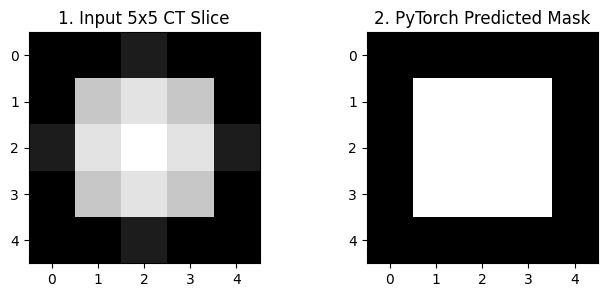

In [37]:
import torch
import matplotlib.pyplot as plt

# Training examples: 3 dark background pixels (y=0) and 3 bright organ pixels (y=1)
x_train = torch.tensor([0.1, 0.2, 0.3, 0.7, 0.8, 0.9])
y_train = torch.tensor([0.0, 0.0, 0.0, 1.0, 1.0, 1.0])

w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)

# Train for 500 epochs
lr = 2.0
for epoch in range(500):
    y_prob = torch.sigmoid(w * x_train + c)
    loss = ((y_prob - y_train) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= lr * w.grad
        c -= lr * c.grad
        w.grad.zero_()
        c.grad.zero_()

print(f"Learned Pixel Classifier: w = {w.item():.2f}, c = {c.item():.2f}")

# Now apply our trained PyTorch model to a 5x5 CT slice!
ct_slice = torch.tensor([
    [0.1, 0.1, 0.2, 0.1, 0.1],
    [0.1, 0.8, 0.9, 0.8, 0.1],
    [0.2, 0.9, 1.0, 0.9, 0.2],
    [0.1, 0.8, 0.9, 0.8, 0.1],
    [0.1, 0.1, 0.2, 0.1, 0.1]
])

with torch.no_grad():
    prob_map = torch.sigmoid(w * ct_slice + c)
    predicted_mask = (prob_map >= 0.5).int()

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.imshow(ct_slice, cmap="gray")
plt.title("1. Input 5x5 CT Slice")

plt.subplot(1, 2, 2)
plt.imshow(predicted_mask, cmap="gray")
plt.title("2. PyTorch Predicted Mask")
plt.show()


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 6.1 and work toward Exercise 6.5.</font> <font color="#334155">These exercises connect tensors, gradients, and <code>torch.sigmoid()</code> directly to medical imaging data.</font></p>

<p><font color="#7135B5"><b>Exercise 6.1 — Convert raw scores into probabilities with <code>torch.sigmoid()</code></b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Given three raw model scores <code>scores = torch.tensor([-10.0, 0.0, 10.0])</code>, apply <code>probs = torch.sigmoid(scores)</code> and print <code>probs</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Watch how <code>-10.0</code> becomes almost <code>0.0</code> (background), <code>0.0</code> becomes exactly <code>0.5</code> (the 50% boundary), and <code>+10.0</code> becomes almost <code>1.0</code> (organ)!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>tensor([4.5398e-05, 5.0000e-01, 9.9995e-01])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>probs = torch.sigmoid(scores)</code> and <code>print(probs)</code>.</font></p>


In [38]:
# Exercise 6.1 — Convert raw scores into probabilities with torch.sigmoid()
scores = torch.tensor([-10.0, 0.0, 10.0])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.2 — Turn a probability map into a binary <code>0</code>/<code>1</code> segmentation mask</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> A PyTorch segmentation model outputs a 2×3 grid of probabilities <code>prob_map = torch.tensor([[0.1, 0.8, 0.2], [0.9, 0.7, 0.3]])</code>. Create an integer mask where probabilities <b>at least <code>0.5</code></b> become <code>1</code> and others become <code>0</code> using <code>mask = (prob_map &gt;= 0.5).int()</code>. Print <code>mask</code> on line 1 and the count of organ pixels <code>mask.sum().item()</code> on line 2.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> The 2×3 <code>0</code>/<code>1</code> tensor followed by <code>3</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>mask = (prob_map &gt;= 0.5).int()</code>. &nbsp; 2. Print <code>mask</code>. &nbsp; 3. Print <code>mask.sum().item()</code>.</font></p>


In [39]:
# Exercise 6.2 — Turn a probability map into a binary 0/1 segmentation mask
prob_map = torch.tensor([
    [0.1, 0.8, 0.2],
    [0.9, 0.7, 0.3]
])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.3 — Compute the Dice Similarity Score using PyTorch Tensors</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> In medical image segmentation, the #1 accuracy metric is the <b>Dice Similarity Score</b>, which ranges from <code>0.0</code> (no overlap) to <code>1.0</code> (perfect match):</font></p>
<p align="center"><font color="#0E7490"><b><code>Dice = (2.0 * overlap) / (pred_mask.sum() + true_mask.sum())</code></b></font></p>
<p><font color="#334155">Given the two 2×2 masks below, compute <code>overlap = (pred_mask * true_mask).sum()</code>, compute <code>dice</code> using the formula above, and print <code>dice.item()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155"><code>pred_mask</code> has 2 ones, <code>true_mask</code> has 2 ones, and they overlap on 2 pixels: <code>(2 * 2) / (2 + 2) = 1.0</code> (a perfect 100% Dice score!).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>1.0</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>overlap = (pred_mask * true_mask).sum()</code>. &nbsp; 2. Compute <code>dice = (2.0 * overlap) / (pred_mask.sum() + true_mask.sum())</code>. &nbsp; 3. Print <code>dice.item()</code>.</font></p>


In [40]:
# Exercise 6.3 — Compute the Dice Similarity Score using PyTorch Tensors
pred_mask = torch.tensor([[1.0, 1.0], [0.0, 0.0]])
true_mask = torch.tensor([[1.0, 1.0], [0.0, 0.0]])
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.4 — Train PyTorch to learn the Hounsfield Unit (HU) calibration rule</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Raw CT scanner numbers <code>x</code> are converted to medical Hounsfield Units <code>y</code> using a linear rule <code>y = w * x + c</code>. Given <code>x = torch.tensor([0.0, 1.0, 2.0, 3.0])</code> (in thousands) and <code>y_true = torch.tensor([-1.0, 0.0, 1.0, 2.0])</code> (in thousands, where <code>w = 1.0</code> and <code>c = -1.0</code>), train <code>w</code> and <code>c</code> for 300 epochs with <code>lr = 0.05</code> and print <code>round(w.item(), 1)</code> and <code>round(c.item(), 1)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>1.0</code> on line 1, and <code>-1.0</code> on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Use the 4-step training loop (`y_pred = w * x + c`, MSE loss, `loss.backward()`, update `w` and `c` with `lr = 0.05` and zero gradients).</font></p>


In [41]:
# Exercise 6.4 — Train PyTorch to learn the Hounsfield Unit (HU) calibration rule
x = torch.tensor([0.0, 1.0, 2.0, 3.0])
y_true = torch.tensor([-1.0, 0.0, 1.0, 2.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)

# Write your 300-epoch training loop below.


<p><font color="#7135B5"><b>Exercise 6.5 — Apply a learned PyTorch classifier to segment a 3×3 mini CT slice</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the trained pixel classifier weights <code>w = 10.0</code> and <code>c = -5.0</code> (which place the 50% boundary right at brightness <code>x = 0.5</code>), compute the probability map <code>probs = torch.sigmoid(w * mini_ct + c)</code> for the provided 3×3 <code>mini_ct</code> slice, convert it to a binary mask <code>mask = (probs &gt;= 0.5).int()</code>, and print <code>mask</code> and <code>mask.sum().item()</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Look at <code>w * x + c</code> when <code>w = 10</code> and <code>c = -5</code>: if a pixel has brightness <code>x = 0.1</code>, then <code>10 * 0.1 - 5 = -4.0</code> (sigmoid is near <code>0</code>). If a pixel has brightness <code>x = 0.9</code>, then <code>10 * 0.9 - 5 = +4.0</code> (sigmoid is near <code>1</code>)!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A 3×3 mask with a <code>1</code> in the center and <code>0</code>s around the border, followed by <code>1</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>probs = torch.sigmoid(w * mini_ct + c)</code>. &nbsp; 2. Compute <code>mask = (probs &gt;= 0.5).int()</code>. &nbsp; 3. Print <code>mask</code> and <code>mask.sum().item()</code>.</font></p>


In [42]:
# Exercise 6.5 — Apply a learned PyTorch classifier to segment a 3x3 mini CT slice
mini_ct = torch.tensor([
    [0.1, 0.2, 0.1],
    [0.2, 0.9, 0.2],
    [0.1, 0.2, 0.1]
])
w = 10.0
c = -5.0
# Write your Python code below.


<hr>
<h1><font color="#177345"><b>Solutions — Check After You Try</b></font></h1>
<p><font color="#177345"><b>Every exercise (1.1 through 6.5) has a complete, self-contained solution below.</b></font> <font color="#334155">Run the code cells below to check your answers and read the comments explaining how each solution works.</font></p>


In [43]:
import numpy as np
import torch

print("=== LESSON 1 SOLUTIONS (y = w * x + c by hand) ===")

# Solution 1.1
w, c, x = 3, 0, 10
y = w * x + c
print("1.1 Expected 30 ->", y)

# Solution 1.2
w, c, x = 2, 1, 6
print("1.2 Expected 13 ->", w * x + c)

# Solution 1.3
x1, y1 = 1, 7
x2, y2 = 2, 11
w = (y2 - y1) / (x2 - x1)
c = y1 - w * x1
print("1.3 Expected 4.0 and 3.0 ->", w, c)

# Solution 1.4
x1, y1 = 10, 60
x2, y2 = 30, 100
w = (y2 - y1) / (x2 - x1)
c = y1 - w * x1
y_new = w * 50 + c
print("1.4 Expected 2.0, 40.0, 140.0 ->", w, c, y_new)

# Solution 1.5
x1, y1 = 1, 90
x2, y2 = 3, 70
w = (y2 - y1) / (x2 - x1)
c = y1 - w * x1
y_new = w * 5 + c
print("1.5 Expected -10.0, 100.0, 50.0 ->", w, c, y_new)

print("\n=== LESSON 2 SOLUTIONS (PyTorch Tensors) ===")

# Solution 2.1
x = torch.tensor([2.0, 4.0, 6.0])
print("2.1 ->", x, "|", x.shape, "|", x.dtype)

# Solution 2.2
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
w, c = 5.0, 2.0
y = w * x + c
print("2.2 ->", y)

# Solution 2.3
volumes = torch.tensor([100.0, 150.0, 200.0, 150.0])
print("2.3 -> Sum:", volumes.sum().item(), "| Mean:", volumes.mean().item())

# Solution 2.4
np_pixels = np.array([0.0, 50.0, 100.0])
t_pixels = torch.tensor(np_pixels, dtype=torch.float32)
scaled = t_pixels / 100.0
print("2.4 ->", scaled)

# Solution 2.5
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y0, y1 = 10.0, 14.0
w = (y1 - y0) / (x[1] - x[0])
c = y0 - w * x[0]
print("2.5 ->", w * x + c)


=== LESSON 1 SOLUTIONS (y = w * x + c by hand) ===
1.1 Expected 30 -> 30
1.2 Expected 13 -> 13
1.3 Expected 4.0 and 3.0 -> 4.0 3.0
1.4 Expected 2.0, 40.0, 140.0 -> 2.0 40.0 140.0
1.5 Expected -10.0, 100.0, 50.0 -> -10.0 100.0 50.0

=== LESSON 2 SOLUTIONS (PyTorch Tensors) ===
2.1 -> tensor([2., 4., 6.]) | torch.Size([3]) | torch.float32
2.2 -> tensor([ 7., 12., 17., 22.])
2.3 -> Sum: 600.0 | Mean: 150.0
2.4 -> tensor([0.0000, 0.5000, 1.0000])
2.5 -> tensor([10., 14., 18., 22.])


In [44]:
import torch

print("=== LESSON 3 SOLUTIONS (Forward Pass & MSE Loss) ===")

# Solution 3.1
x = torch.tensor([1.0, 2.0, 3.0])
w, c = 3.0, 1.0
y_pred = w * x + c
print("3.1 ->", y_pred)

# Solution 3.2
y_pred = torch.tensor([2.0, 4.0, 6.0])
y_true = torch.tensor([4.0, 6.0, 8.0])
loss = ((y_pred - y_true) ** 2).mean()
print("3.2 ->", loss.item())

# Solution 3.3
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([6.0, 11.0, 16.0])
loss_a = (((4.0 * x + 1.0) - y_true) ** 2).mean().item()
loss_b = (((5.0 * x + 1.0) - y_true) ** 2).mean().item()
print("3.3 -> Guess A Loss:", round(loss_a, 2), "| Guess B Loss:", loss_b)

# Solution 3.4
y_pred = torch.tensor([10.0, 20.0, 30.0])
y_true = torch.tensor([13.0, 23.0, 33.0])
loss_fn = torch.nn.MSELoss()
loss = loss_fn(y_pred, y_true)
print("3.4 ->", loss.item())

# Solution 3.5
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([9.0, 13.0, 17.0])
w, c = 4.0, 5.0
y_pred = w * x + c
loss = ((y_pred - y_true) ** 2).mean().item()
print("3.5 ->", loss)

print("\n=== LESSON 4 SOLUTIONS (Autograd & .backward()) ===")

# Solution 4.1
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)
print("4.1 ->", w.requires_grad, c.requires_grad)

# Solution 4.2
x = torch.tensor(2.0)
y_true = torch.tensor(10.0)
w = torch.tensor(1.0, requires_grad=True)
loss = (w * x - y_true) ** 2
loss.backward()
print("4.2 ->", w.grad.item())

# Solution 4.3
x = torch.tensor(2.0)
y_true = torch.tensor(10.0)
w = torch.tensor(8.0, requires_grad=True)
loss = (w * x - y_true) ** 2
loss.backward()
print("4.3 ->", w.grad.item())

# Solution 4.4
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([4.0, 7.0, 10.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)
loss = ((w * x + c - y_true) ** 2).mean()
loss.backward()
print("4.4 -> w.grad:", w.grad.item(), "| c.grad:", c.grad.item())

# Solution 4.5
x = torch.tensor(2.0)
y_true = torch.tensor(10.0)
w = torch.tensor(1.0, requires_grad=True)
loss = (w * x - y_true) ** 2
loss.backward()
with torch.no_grad():
    w -= 0.1 * w.grad
print("4.5 -> Updated w:", round(w.item(), 2))


=== LESSON 3 SOLUTIONS (Forward Pass & MSE Loss) ===
3.1 -> tensor([ 4.,  7., 10.])
3.2 -> 4.0
3.3 -> Guess A Loss: 4.67 | Guess B Loss: 0.0
3.4 -> 9.0
3.5 -> 0.0

=== LESSON 4 SOLUTIONS (Autograd & .backward()) ===
4.1 -> True True
4.2 -> -32.0
4.3 -> 24.0
4.4 -> w.grad: -32.0 | c.grad: -14.000000953674316
4.5 -> Updated w: 4.2


=== LESSON 5 SOLUTIONS (Training Loops) ===
5.1 -> Learned w: 3.0
5.2 -> Learned w: 2.0 | Learned c: 1.0
5.3 -> Predicted y for x=10: 43.0
5.4 -> nn.Linear w: 5.0 | c: 1.0


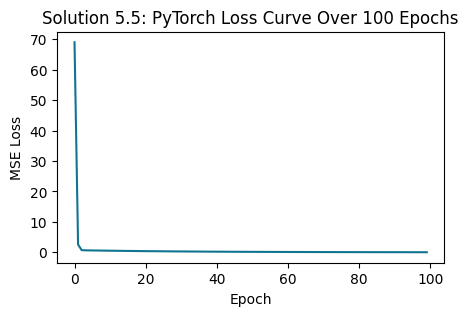


=== LESSON 6 SOLUTIONS (Medical Imaging Workflow) ===
6.1 -> tensor([4.5398e-05, 5.0000e-01, 9.9995e-01])
6.2 -> Mask:
 tensor([[0, 1, 0],
        [1, 1, 0]], dtype=torch.int32) 
Count: 3
6.3 -> Dice Score: 1.0
6.4 -> HU w: 1.0 | c: -1.0
6.5 -> Segmented 3x3 Mask:
 tensor([[0, 0, 0],
        [0, 1, 0],
        [0, 0, 0]], dtype=torch.int32) 
Organ pixels: 1


In [45]:
import torch
import matplotlib.pyplot as plt

print("=== LESSON 5 SOLUTIONS (Training Loops) ===")

# Solution 5.1
x = torch.tensor([1.0, 2.0, 3.0])
y_true = torch.tensor([3.0, 6.0, 9.0])
w = torch.tensor(0.0, requires_grad=True)
for _ in range(100):
    loss = ((w * x - y_true) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= 0.05 * w.grad
        w.grad.zero_()
print("5.1 -> Learned w:", round(w.item(), 2))

# Solution 5.2
x = torch.tensor([0.0, 1.0, 2.0, 3.0])
y_true = torch.tensor([1.0, 3.0, 5.0, 7.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)
for _ in range(300):
    loss = ((w * x + c - y_true) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= 0.05 * w.grad
        c -= 0.05 * c.grad
        w.grad.zero_()
        c.grad.zero_()
print("5.2 -> Learned w:", round(w.item(), 2), "| Learned c:", round(c.item(), 2))

# Solution 5.3
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y_true = torch.tensor([7.0, 11.0, 15.0, 19.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)
for _ in range(400):
    loss = ((w * x + c - y_true) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= 0.05 * w.grad
        c -= 0.05 * c.grad
        w.grad.zero_()
        c.grad.zero_()
y_10 = w.item() * 10.0 + c.item()
print("5.3 -> Predicted y for x=10:", round(y_10, 1))

# Solution 5.4
torch.manual_seed(0)
x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y_true = torch.tensor([[6.0], [11.0], [16.0], [21.0]])
model = torch.nn.Linear(1, 1)
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
for _ in range(400):
    optimizer.zero_grad()
    loss = loss_fn(model(x), y_true)
    loss.backward()
    optimizer.step()
print("5.4 -> nn.Linear w:", round(model.weight.item(), 1), "| c:", round(model.bias.item(), 1))

# Solution 5.5
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y_true = torch.tensor([5.0, 7.0, 9.0, 11.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)
loss_history = []
for _ in range(100):
    loss = ((w * x + c - y_true) ** 2).mean()
    loss_history.append(loss.item())
    loss.backward()
    with torch.no_grad():
        w -= 0.05 * w.grad
        c -= 0.05 * c.grad
        w.grad.zero_()
        c.grad.zero_()
plt.figure(figsize=(5, 3))
plt.plot(loss_history, color="#0E7490")
plt.title("Solution 5.5: PyTorch Loss Curve Over 100 Epochs")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.show()

print("\n=== LESSON 6 SOLUTIONS (Medical Imaging Workflow) ===")

# Solution 6.1
scores = torch.tensor([-10.0, 0.0, 10.0])
probs = torch.sigmoid(scores)
print("6.1 ->", probs)

# Solution 6.2
prob_map = torch.tensor([[0.1, 0.8, 0.2], [0.9, 0.7, 0.3]])
mask = (prob_map >= 0.5).int()
print("6.2 -> Mask:\n", mask, "\nCount:", mask.sum().item())

# Solution 6.3
pred_mask = torch.tensor([[1.0, 1.0], [0.0, 0.0]])
true_mask = torch.tensor([[1.0, 1.0], [0.0, 0.0]])
overlap = (pred_mask * true_mask).sum()
dice = (2.0 * overlap) / (pred_mask.sum() + true_mask.sum())
print("6.3 -> Dice Score:", dice.item())

# Solution 6.4
x = torch.tensor([0.0, 1.0, 2.0, 3.0])
y_true = torch.tensor([-1.0, 0.0, 1.0, 2.0])
w = torch.tensor(0.0, requires_grad=True)
c = torch.tensor(0.0, requires_grad=True)
for _ in range(300):
    loss = ((w * x + c - y_true) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= 0.05 * w.grad
        c -= 0.05 * c.grad
        w.grad.zero_()
        c.grad.zero_()
print("6.4 -> HU w:", round(w.item(), 1), "| c:", round(c.item(), 1))

# Solution 6.5
mini_ct = torch.tensor([[0.1, 0.2, 0.1], [0.2, 0.9, 0.2], [0.1, 0.2, 0.1]])
probs = torch.sigmoid(10.0 * mini_ct - 5.0)
mask = (probs >= 0.5).int()
print("6.5 -> Segmented 3x3 Mask:\n", mask, "\nOrgan pixels:", mask.sum().item())


<hr>
<h1><font color="#1D4ED8"><b>Quick Reference — PyTorch Intro Cheat Sheet</b></font></h1>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:12px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Concept</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>PyTorch Command</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Plain-English Meaning</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. The Linear Rule</b></td>
  <td style="padding:7px"><code>y = w * x + c</code></td>
  <td style="padding:7px"><code>w</code> is the multiplier (how much <code>y</code> jumps when <code>x</code> goes up by 1), and <code>c</code> is the starting value when <code>x = 0</code>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Create a Tensor</b></td>
  <td style="padding:7px"><code>x = torch.tensor([1.0, 2.0, 3.0])</code></td>
  <td style="padding:7px">Creates a decimal (<code>float32</code>) tensor. Use <code>.item()</code> to extract a single Python number.</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. Forward Pass &amp; Loss</b></td>
  <td style="padding:7px"><code>y_pred = w * x + c</code><br><code>loss = ((y_pred - y_true) ** 2).mean()</code></td>
  <td style="padding:7px">Predicts <code>y</code> using our current guess and measures the Mean Squared Error (<code>0.0</code> = perfect).</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. Autograd Compass</b></td>
  <td style="padding:7px"><code>w = torch.tensor(0.0, requires_grad=True)</code><br><code>loss.backward()</code></td>
  <td style="padding:7px">Tracks <code>w</code> and computes <code>w.grad</code> (negative = push <code>w</code> UP; positive = push <code>w</code> DOWN).</td>
</tr>
<tr>
  <td style="padding:7px"><b>5. Update &amp; Reset</b></td>
  <td style="padding:7px"><code>with torch.no_grad():</code><br>&nbsp;&nbsp;<code>w -= lr * w.grad</code><br>&nbsp;&nbsp;<code>w.grad.zero_()</code></td>
  <td style="padding:7px">Nudges <code>w</code> toward the truth and resets the gradient compass to zero for the next epoch.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>6. Pixel Probability</b></td>
  <td style="padding:7px"><code>probs = torch.sigmoid(w * x + c)</code><br><code>mask = (probs &gt;= 0.5).int()</code></td>
  <td style="padding:7px">Squashes scores between <code>0.0</code> and <code>1.0</code> and thresholds at 50% to create a binary segmentation mask.</td>
</tr>
</table>